In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("../data/retail_sales_dataset.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (1000, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [3]:
# Display dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 100.2 KB


In [4]:
# Count missing values in each column
print(df.isnull().sum())

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [5]:
# Count duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [6]:
# Statistical summary of numerical columns
df.describe()

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [7]:
# Number of unique values in each column
print(df.nunique())

Transaction ID      1000
Date                 345
Customer ID         1000
Gender                 2
Age                   47
Product Category       3
Quantity               4
Price per Unit         5
Total Amount          18
dtype: int64


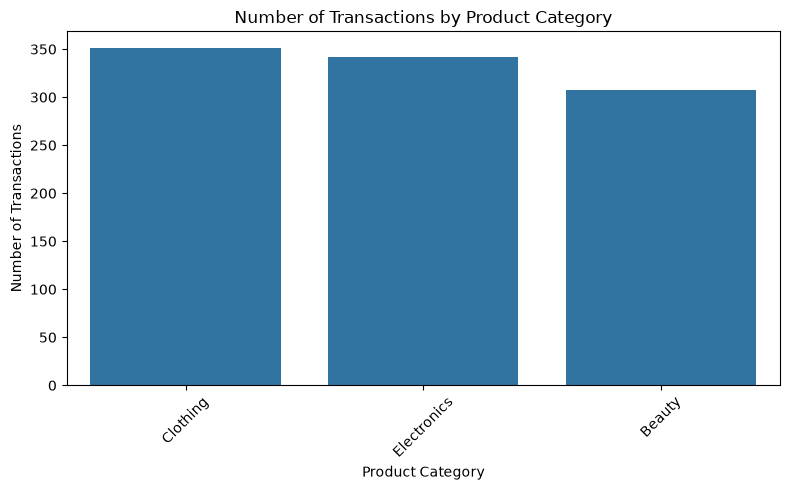

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Product Category",
    order=df["Product Category"].value_counts().index
)

plt.title("Number of Transactions by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64


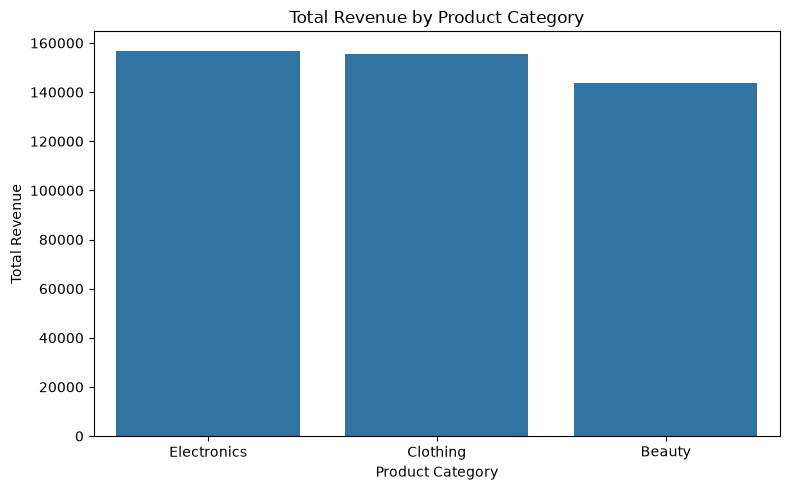

In [9]:
# Calculate total revenue for each product category
category_revenue = (
    df.groupby("Product Category")["Total Amount"]
    .sum()
    .sort_values(ascending=False)
)

print(category_revenue)

# Visualize revenue by category
plt.figure(figsize=(8, 5))

sns.barplot(
    x=category_revenue.index,
    y=category_revenue.values
)

plt.title("Total Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.show()

Month
1     36980
2     44060
3     28990
4     33870
5     53150
6     36715
7     35465
8     36960
9     23620
10    46580
11    34920
12    44690
Name: Total Amount, dtype: int64


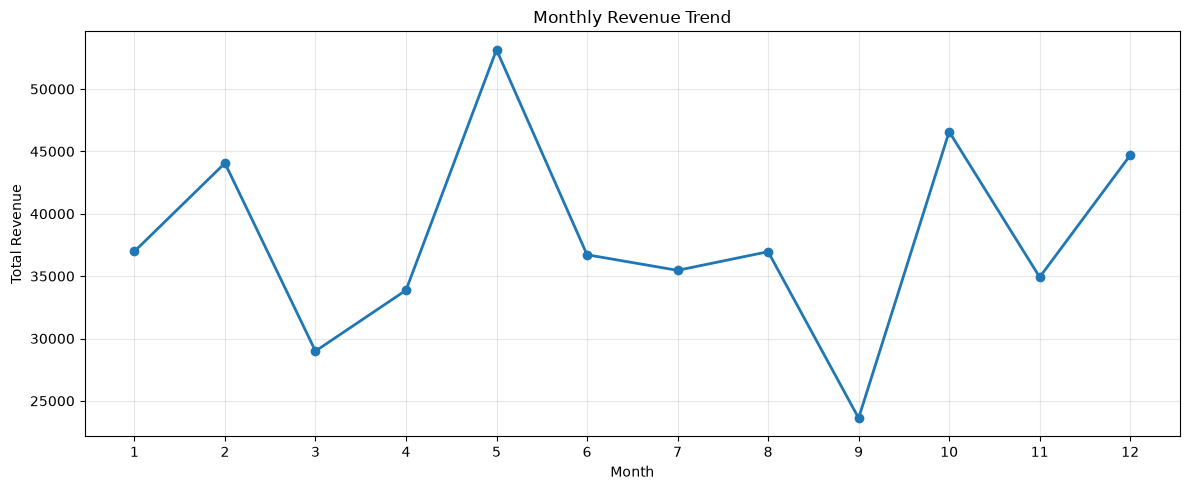

In [10]:
# Convert Date column to datetime
df["Date"] = pd.to_datetime(df["Date"])

# Extract month and month name
df["Month"] = df["Date"].dt.month
df["Month Name"] = df["Date"].dt.strftime("%B")

# Calculate monthly revenue in chronological order
monthly_sales = (
    df.groupby("Month")["Total Amount"]
    .sum()
)

# Display results
print(monthly_sales)

# Plot monthly sales
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
# Calculate key business metrics

total_revenue = df["Total Amount"].sum()
total_transactions = df["Transaction ID"].nunique()
total_customers = df["Customer ID"].nunique()
total_units_sold = df["Quantity"].sum()
average_transaction_value = total_revenue / total_transactions

print("===== RETAIL SALES KPI REPORT =====")
print(f"Total Revenue: ₹{total_revenue:,.2f}")
print(f"Total Transactions: {total_transactions:,}")
print(f"Unique Customers: {total_customers:,}")
print(f"Total Units Sold: {total_units_sold:,}")
print(f"Average Transaction Value: ₹{average_transaction_value:,.2f}")
print(f"Average Customer Age: {df['Age'].mean():.1f} years")

===== RETAIL SALES KPI REPORT =====
Total Revenue: ₹456,000.00
Total Transactions: 1,000
Unique Customers: 1,000
Total Units Sold: 2,514
Average Transaction Value: ₹456.00
Average Customer Age: 41.4 years


In [12]:
# Revenue and transaction count by gender
gender_analysis = df.groupby("Gender").agg(
    Total_Revenue=("Total Amount", "sum"),
    Transactions=("Transaction ID", "nunique"),
    Average_Spending=("Total Amount", "mean")
).round(2)

print("CUSTOMER ANALYSIS BY GENDER")
display(gender_analysis)

CUSTOMER ANALYSIS BY GENDER


,Total_Revenue,Transactions,Average_Spending
Gender,,,
Female,232840,510,456.55
Male,223160,490,455.43


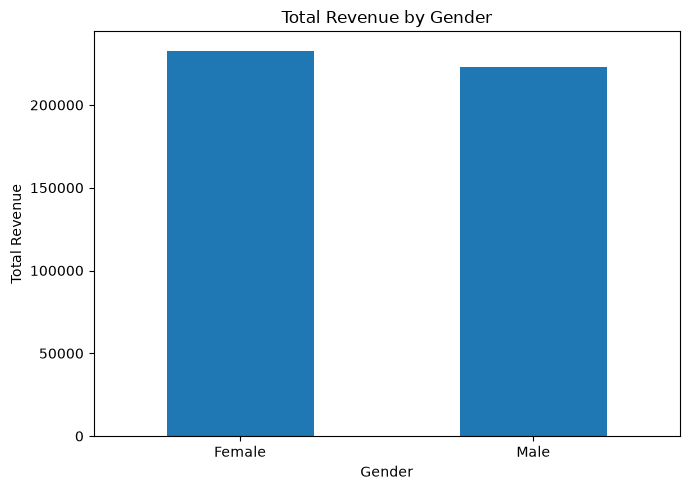

In [13]:
gender_analysis["Total_Revenue"].plot(
    kind="bar",
    figsize=(7, 5),
    title="Total Revenue by Gender",
    ylabel="Total Revenue",
    xlabel="Gender",
    rot=0
)

plt.tight_layout()
plt.show()

In [14]:
# Create age groups
df["Age Group"] = pd.cut(
    df["Age"],
    bins=[0, 20, 30, 40, 50, 60, 100],
    labels=[
        "Under 20",
        "21-30",
        "31-40",
        "41-50",
        "51-60",
        "Above 60"
    ],
    include_lowest=True
)

# Analyze each age group
age_analysis = df.groupby(
    "Age Group", observed=False
).agg(
    Customers=("Customer ID", "nunique"),
    Total_Revenue=("Total Amount", "sum"),
    Average_Spending=("Total Amount", "mean")
).round(2)

display(age_analysis)

,Customers,Total_Revenue,Average_Spending
Age Group,,,
Under 20,63,34730,551.27
21-30,210,98215,467.69
31-40,193,95950,497.15
41-50,221,93795,424.41
51-60,220,100085,454.93
Above 60,93,33225,357.26


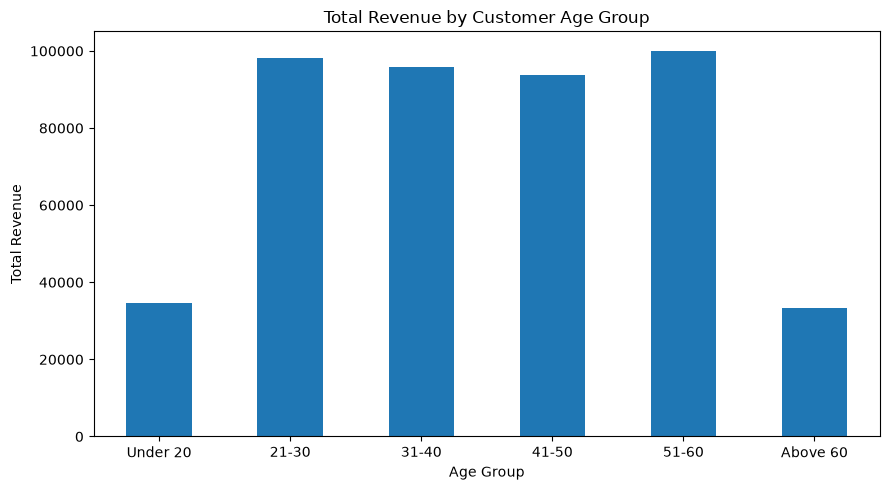

In [15]:
age_analysis["Total_Revenue"].plot(
    kind="bar",
    figsize=(9, 5),
    title="Total Revenue by Customer Age Group",
    ylabel="Total Revenue",
    xlabel="Age Group",
    rot=0
)

plt.tight_layout()
plt.show()

In [16]:
# Product category performance
product_analysis = df.groupby("Product Category").agg(
    Transactions=("Transaction ID", "nunique"),
    Units_Sold=("Quantity", "sum"),
    Total_Revenue=("Total Amount", "sum"),
    Average_Transaction_Value=("Total Amount", "mean")
).sort_values(
    by="Total_Revenue", ascending=False
).round(2)

display(product_analysis)

,Transactions,Units_Sold,Total_Revenue,Average_Transaction_Value
Product Category,,,,
Electronics,342,849,156905,458.79
Clothing,351,894,155580,443.25
Beauty,307,771,143515,467.48


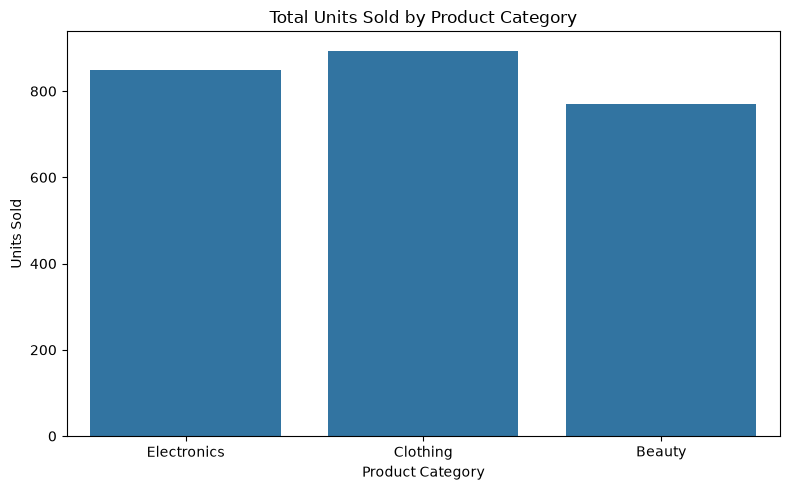

In [17]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=product_analysis.reset_index(),
    x="Product Category",
    y="Units_Sold"
)

plt.title("Total Units Sold by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Units Sold")
plt.tight_layout()
plt.show()